# DL-10 v3: one method at a time

This notebook reads `locked/baseline.keras` and writes only new files under `test/`. It does not write `locked/`, `current/`, `old/`, or `RESULTS.md`. If a target name already exists, the save stops.

Each later part reloads the locked baseline, shows the method on one tensor, then applies the same settings as the v2 rows.


## Contents

- [Part 0. Baseline](#part-0)
- [Shared helpers](#shared-helpers)
- [Part 1. Pruning](#part-1)
- [Part 2. INT8 post-training quantization](#part-2)
- [Part 3. Distillation](#part-3)
- [Hard-label student](#hard-label)
- [Part 4. Stacking](#part-4)
- [Final comparison](#final)


<a id="part-0"></a>
## Part 0. Baseline

**Goal:** Confirm the locked file is the reference: SHA-256 a7d3dc90… and test accuracy 0.9158.

**Input:** `locked/baseline.keras`, read only. The copy `locked/baseline_v2_locked.keras` is checked and not loaded for training.

**Process:**
1. Set `TF_USE_LEGACY_KERAS=1` before importing TensorFlow.
2. Build the 54,000 / 6,000 / 10,000 split with no shuffle.
3. Load the locked file, print its SHA-256, and evaluate the 10,000 test images.

**Output:** No file. This part does not train and does not save.

**Measurements:** test accuracy, raw .tflite KB, raw cut % = 1 − raw_KB / 1690.108, gzip KB, gzip cut %, median p50 and p95 latency, and peak memory. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor. Raw cut uses `raw_KB` from `results/results.csv`. The denominator 1690.108 is the float baseline `raw_KB`.

**Standard:** this part is the reference, 0.9158. The accuracy bar and both size bars are not scored on this load. Keras–TFLite is checked once here: `results/equivalence.json` records max output difference 1.7583370208740234e-6 on 10,000 official test images between `locked/baseline.keras` and `current/baseline_v2.tflite`, which is ≤ 1e-4, PASS.


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gzip
import hashlib
import math
import time
import numpy as np
import tensorflow as tf
import tf_keras

ROOT = str(__import__("pathlib").Path.cwd().parent)
LOCKED = os.path.join(ROOT, "locked/baseline.keras")
LOCKED_COPY = os.path.join(ROOT, "locked/baseline_v2_locked.keras")
TEST = os.path.join(ROOT, "test")
EXPECTED_SHA = "a7d3dc90da3bbf12aaece24ab57a014a216f3cff326d20c0d146434e69dfdb7b"
REF_ACC = 0.9158
print("tf", tf.__version__)
print("tf_keras", tf_keras.__version__)
print("legacy", os.environ["TF_USE_LEGACY_KERAS"])


I0000 00:00:1794975143.449104  119076 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794975144.661642  119076 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tf 2.21.0
tf_keras 2.21.0
legacy 1


### Data

**What:** build the 54,000 / 6,000 / 10,000 split.

**Why:** the same split as the v2 rows. There is no shuffle, so the seed does not move images between splits.


In [2]:
tf.random.set_seed(42)
np.random.seed(42)
(x_train_full, y_train_full), (x_te, y_te) = tf.keras.datasets.fashion_mnist.load_data()
x_train_full = (x_train_full / 255.0).astype("float32")[..., None]
x_te = (x_te / 255.0).astype("float32")[..., None]
x_tr, y_tr = x_train_full[:-6000], y_train_full[:-6000]
x_val, y_val = x_train_full[-6000:], y_train_full[-6000:]
assert len(x_tr) == 54000 and len(x_val) == 6000 and len(x_te) == 10000
print(x_tr.shape, x_val.shape, x_te.shape)


(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


### Load the locked baseline

**What:** print the SHA-256, then evaluate the official test set.

**Why:** this is the reference, test accuracy 0.9158. The cell does not train and does not save.


In [3]:
sha = hashlib.sha256(open(LOCKED, "rb").read()).hexdigest()
print("sha256", sha)
if not sha.startswith("a7d3dc90") or sha != EXPECTED_SHA:
    raise SystemExit("locked baseline hash mismatch")
copy_sha = hashlib.sha256(open(LOCKED_COPY, "rb").read()).hexdigest()
print("copy matches", copy_sha == sha)
baseline = tf_keras.models.load_model(LOCKED)
test_acc = float(baseline.evaluate(x_te, y_te, verbose=0)[1])
print("test acc", round(test_acc, 4))
print("expected reference", REF_ACC)
print("loaded only, not saved")


sha256 a7d3dc90da3bbf12aaece24ab57a014a216f3cff326d20c0d146434e69dfdb7b
copy matches True
test acc 0.9158
expected reference 0.9158
loaded only, not saved


<a id="shared-helpers"></a>
## Shared helpers

**What:** functions for a safe save, a float or INT8 conversion, latency, peak memory, and one measurement row.

**Why:** every later part uses the same procedure. This cell does not train and does not save a model. It reads `current/baseline_v2.tflite` only to record that file's gzip size.

Peak memory stays in this notebook. Each reading is a fresh process that imports the TFLite wrapper and NumPy, runs 200 inferences, and reports `VmHWM`. An empty process, imports only, is the floor. The reported value is the median of three model readings minus the median of three empty readings. That is the same rule as `RESULTS.md`.


In [4]:
import tensorflow_model_optimization as tfmot

ROWS = []
BASE_GZIP = None

def gzip_size(payload):
    return len(gzip.compress(payload, compresslevel=9, mtime=0))

def new_test_path(name):
    path = os.path.join(TEST, name)
    if os.path.dirname(path) != TEST:
        raise RuntimeError("refusing a path outside test/: " + path)
    if os.path.exists(path):
        raise FileExistsError("refusing to overwrite " + path)
    return path

def save_bytes(name, payload):
    path = new_test_path(name)
    with open(path, "wb") as handle:
        handle.write(payload)
    return path

def save_keras(model, name):
    path = new_test_path(name)
    model.save(path)
    return path

def make_cnn(width):
    return tf_keras.Sequential([
        tf_keras.layers.Input((28, 28, 1)),
        tf_keras.layers.Conv2D(width, 3, activation="relu", padding="same"),
        tf_keras.layers.MaxPooling2D(),
        tf_keras.layers.Conv2D(2 * width, 3, activation="relu", padding="same"),
        tf_keras.layers.MaxPooling2D(),
        tf_keras.layers.Flatten(),
        tf_keras.layers.Dense(128, activation="relu"),
        tf_keras.layers.Dropout(0.3),
        tf_keras.layers.Dense(10, activation="softmax"),
    ])

def first_kernel(model):
    for layer in model.layers:
        weights = layer.get_weights()
        if weights:
            return layer.name, weights[0]
    raise RuntimeError("no kernel")

def convert_float(model, name):
    payload = tf.lite.TFLiteConverter.from_keras_model(model).convert()
    return save_bytes(name, payload), payload

def convert_int8(model, name, calibration_count=300):
    def representative():
        for index in range(calibration_count):
            yield [np.ascontiguousarray(x_tr[index:index + 1])]
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8
    payload = converter.convert()
    return save_bytes(name, payload), payload

def quantize_input(images, detail):
    if detail["dtype"] == np.float32:
        return images.astype(np.float32)
    scale, zero = detail["quantization"]
    values = np.round(images / scale + zero)
    info = np.iinfo(detail["dtype"])
    return np.clip(values, info.min, info.max).astype(detail["dtype"])

def dequantize_output(values, detail):
    if detail["dtype"] == np.float32:
        return values
    scale, zero = detail["quantization"]
    return scale * (values.astype(np.float32) - zero)

def make_interpreter(path):
    interpreter = tf.lite.Interpreter(model_path=path, num_threads=1)
    interpreter.allocate_tensors()
    return interpreter

def tflite_accuracy(path, images, labels):
    interpreter = make_interpreter(path)
    input_detail = interpreter.get_input_details()[0]
    output_detail = interpreter.get_output_details()[0]
    batch = 256
    try:
        interpreter.resize_tensor_input(input_detail["index"], [batch, 28, 28, 1], strict=True)
        interpreter.allocate_tensors()
    except (ValueError, RuntimeError):
        batch = 1
    correct = 0
    for start in range(0, len(labels), batch):
        chunk = images[start:start + batch]
        input_detail = interpreter.get_input_details()[0]
        output_detail = interpreter.get_output_details()[0]
        if len(chunk) != batch:
            interpreter.resize_tensor_input(input_detail["index"], [len(chunk), 28, 28, 1], strict=True)
            interpreter.allocate_tensors()
            input_detail = interpreter.get_input_details()[0]
            output_detail = interpreter.get_output_details()[0]
        interpreter.set_tensor(input_detail["index"], quantize_input(chunk, input_detail))
        interpreter.invoke()
        logits = dequantize_output(interpreter.get_tensor(output_detail["index"]), output_detail)
        correct += int((logits.argmax(axis=-1) == labels[start:start + len(chunk)]).sum())
    return correct / len(labels)

def latency_medians(path):
    interpreter = make_interpreter(path)
    detail = interpreter.get_input_details()[0]
    if list(detail["shape"]) != [1, 28, 28, 1]:
        interpreter.resize_tensor_input(detail["index"], [1, 28, 28, 1], strict=True)
        interpreter.allocate_tensors()
    sample = x_te[0][None, ...]
    p50, p95 = [], []
    for _ in range(3):
        input_detail = interpreter.get_input_details()[0]
        output_detail = interpreter.get_output_details()[0]
        feed = quantize_input(sample, input_detail)
        for _ in range(20):
            interpreter.set_tensor(input_detail["index"], feed)
            interpreter.invoke()
            interpreter.get_tensor(output_detail["index"])
        samples = []
        for _ in range(200):
            start = time.perf_counter()
            interpreter.set_tensor(input_detail["index"], feed)
            interpreter.invoke()
            interpreter.get_tensor(output_detail["index"])
            samples.append((time.perf_counter() - start) * 1000)
        p50.append(float(np.percentile(samples, 50)))
        p95.append(float(np.percentile(samples, 95)))
    p50.sort(); p95.sort()
    return p50[1], p95[1]

import subprocess
import sys
import matplotlib
try:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None:
        shell.run_line_magic("matplotlib", "inline")
    else:
        matplotlib.use("Agg")
except Exception:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

SO_DIR = os.path.join(os.path.dirname(tf.__file__), "lite", "python")
SAMPLE_NPY = "/tmp/dl10_latency_sample.npy"
if not os.path.exists(SAMPLE_NPY):
    np.save(SAMPLE_NPY, x_te[0])
FLOOR_KB = None

VM_CHILD = r"""
import os, sys
sys.path.insert(0, os.environ["SO_DIR"])
import _pywrap_tensorflow_interpreter_wrapper as wrap
import numpy as np
model = os.environ.get("MODEL") or ""
if model:
    interp = wrap.CreateWrapperFromFile(model, 1, [], [], False, False, 1, False)
    if not interp:
        raise SystemExit("create failed")
    interp.AllocateTensors()
    in_idx = int(list(interp.InputIndices())[0])
    out_idx = int(list(interp.OutputIndices())[0])
    shape = [int(v) for v in interp.TensorSize(in_idx, 0)]
    if shape != [1, 28, 28, 1]:
        interp.ResizeInputTensor(in_idx, np.array([1, 28, 28, 1], np.int32), True)
        interp.AllocateTensors()
    image = np.load(os.environ["NPY"]).astype(np.float32)[None, ...]
    quant = interp.TensorQuantization(in_idx, 0)
    dtype = np.dtype(interp.TensorType(in_idx, 0))
    if dtype == np.int8:
        scale, zero = float(quant[0]), int(quant[1])
        feed = np.clip(np.round(image / scale + zero), -128, 127).astype(np.int8)
    elif dtype == np.float32:
        feed = image
    else:
        raise SystemExit("unexpected input dtype " + dtype.name)
    for _ in range(200):
        interp.SetTensor(in_idx, feed)
        interp.Invoke()
        interp.GetTensor(out_idx, 0)
if "tensorflow" in sys.modules or any(name.startswith("tensorflow.") for name in sys.modules):
    raise SystemExit("tensorflow was imported")
vm = None
with open("/proc/self/status") as status:
    for line in status:
        if line.startswith("VmHWM:"):
            vm = int(line.split()[1])
print(vm)
"""

def save_plot(fig, name):
    folder = os.path.join(TEST, "plots")
    os.makedirs(folder, exist_ok=True)
    path = os.path.join(folder, name)
    if os.path.dirname(path) != folder:
        raise RuntimeError("refusing a plot path outside test/plots: " + path)
    if os.path.exists(path):
        raise FileExistsError("refusing to overwrite " + path)
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path

def _vmhwm_once(model_path):
    env = os.environ.copy()
    env["SO_DIR"] = SO_DIR
    env["MODEL"] = model_path
    env["NPY"] = SAMPLE_NPY
    env["TF_CPP_MIN_LOG_LEVEL"] = "3"
    completed = subprocess.run(
        [sys.executable, "-c", VM_CHILD],
        env=env, check=True, capture_output=True, text=True,
    )
    return int(completed.stdout.strip().splitlines()[-1])

def peak_delta(model_path):
    global FLOOR_KB
    if FLOOR_KB is None:
        empty = sorted(_vmhwm_once("") for _ in range(3))
        FLOOR_KB = empty[1]
        print("empty floor kB", FLOOR_KB, empty)
    readings = sorted(_vmhwm_once(model_path) for _ in range(3))
    return readings[1], readings[1] - FLOOR_KB

RAW_BASE_KB = 1690.108  # results/results.csv raw_KB of float baseline

def raw_cut_pct(raw_kb):
    return (1.0 - raw_kb / RAW_BASE_KB) * 100.0

def bar_flags(row):
    acc_ok = row["loss_pp"] <= 2.0
    raw_ok = row["raw_cut"] >= 50.0
    gzip_ok = row["size_cut"] >= 50.0
    return acc_ok, raw_ok, gzip_ok

def verdict(row):
    if row.get("reference"):
        return "reference"
    acc_ok, raw_ok, gzip_ok = bar_flags(row)
    if acc_ok and raw_ok and gzip_ok:
        return "PASS"
    if not acc_ok:
        return "FAIL (acc)"
    if not raw_ok:
        return "FAIL (raw)"
    return "FAIL (gzip)"

def measure_saved(name, path):
    payload = open(path, "rb").read()
    acc = tflite_accuracy(path, x_te, y_te)
    raw = len(payload)
    gzip_n = gzip_size(payload)
    p50, p95 = latency_medians(path)
    vm_median, vm_delta = peak_delta(path)
    row = {
        "name": name,
        "file": os.path.basename(path),
        "test_acc": acc,
        "loss_pp": (REF_ACC - acc) * 100,
        "raw_kb": raw / 1000,
        "gzip_kb": gzip_n / 1000,
        "raw_cut": raw_cut_pct(raw / 1000),
        "size_cut": (BASE_GZIP - gzip_n) / BASE_GZIP * 100,
        "p50_ms": p50,
        "p95_ms": p95,
        "vmhwm_kb": vm_median,
        "vm_delta_kb": vm_delta,
        "reference": False,
    }
    ROWS.append(row)
    print_row(row)
    return row

def print_row(row):
    print(
        f"{row['name']}: test {row['test_acc']:.4f}, loss {row['loss_pp']:.2f} pp, "
        f"raw {row['raw_kb']:.3f} KB, raw cut {row['raw_cut']:.2f}%, "
        f"gzip {row['gzip_kb']:.3f} KB, gzip cut {row['size_cut']:.2f}%, "
        f"p50 {row['p50_ms']:.3f} ms, p95 {row['p95_ms']:.3f} ms, "
        f"VmHWM-floor {row['vm_delta_kb']} kB"
    )
    if row.get("reference"):
        print("accuracy bar (<= 2 pp): not applied")
        print("raw bar (>= 50% raw cut): not applied")
        print("gzip bar (>= 50% gzip cut): not applied")
        print("Keras-TFLite bar (<= 1e-4): PASS, results/equivalence.json value 1.7583370208740234e-6, once on this float model")
        print("row: reference")
        return
    acc_ok, raw_ok, gzip_ok = bar_flags(row)
    print("accuracy bar (<= 2 pp):", "PASS" if acc_ok else "FAIL")
    print("raw bar (>= 50% raw cut):", "PASS" if raw_ok else "FAIL")
    print("gzip bar (>= 50% gzip cut):", "PASS" if gzip_ok else "FAIL")
    print("verdict:", verdict(row))

def reload_baseline():
    model = tf_keras.models.load_model(LOCKED)
    digest = hashlib.sha256(open(LOCKED, "rb").read()).hexdigest()
    if digest != EXPECTED_SHA:
        raise SystemExit("locked baseline hash mismatch")
    return model

with open(os.path.join(ROOT, "current/baseline_v2.tflite"), "rb") as handle:
    BASE_GZIP = gzip_size(handle.read())
print("helpers ready, baseline gzip bytes", BASE_GZIP)


helpers ready, baseline gzip bytes 1567603


<a id="part-1"></a>
## Part 1. Pruning

**Goal:** Remove small-magnitude weights from the baseline and measure the float pruned file.

**Input:** `locked/baseline.keras`, reloaded for the demo and again for the full run.

**Process:**
1. On a copy of the first kernel, set the smallest 70 percent of magnitudes to zero and plot the histogram.
2. Apply `PolynomialDecay` with final sparsity 0.7, power 3, frequency 100, and `end_step` 1688.
3. Fine-tune 4 epochs with Adam at learning rate 0.0001 and hard labels. Keep the last epoch.
4. Strip the pruning wrappers, save the model, convert it to float TFLite, and measure that file.

**Output:** `test/v3_pruned.keras`, `test/v3_pruned.tflite`, and `test/plots/v3_prune_hist.png`.

**Measurements:** test accuracy, raw .tflite KB, raw cut % = 1 − raw_KB / 1690.108, gzip KB, gzip cut %, median p50 and p95 latency, and peak memory. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor. Raw cut uses `raw_KB` from `results/results.csv`. The denominator 1690.108 is the float baseline `raw_KB`.

**Standard:** a compressed row passes only if the accuracy drop against 0.9158 is at most 2 percentage points, the raw cut is at least 50 percent, and the gzip cut is at least 50 percent. Keras–TFLite max output difference ≤ 1e-4 is checked once on the float model, in Part 0, from `results/equivalence.json`. It is not scored again on this row.


### One-layer demo

**What:** zero the smallest 70 percent of magnitudes in a copy of the first kernel, and print eight values before and after.

**Why:** this shows what magnitude pruning does to one tensor. The locked file is reloaded and is not changed.


layer conv2d
before [ 0.15    0.1364 -0.1923  0.1033 -0.1203  0.0848 -0.0421  0.1393]
after [ 0.      0.     -0.1923  0.      0.      0.      0.      0.    ]
zero fraction in this copy 0.6979166666666666
locked file was not changed


FileExistsError: refusing to overwrite /home/haiminh/dl-10/test/plots/v3_prune_hist.png

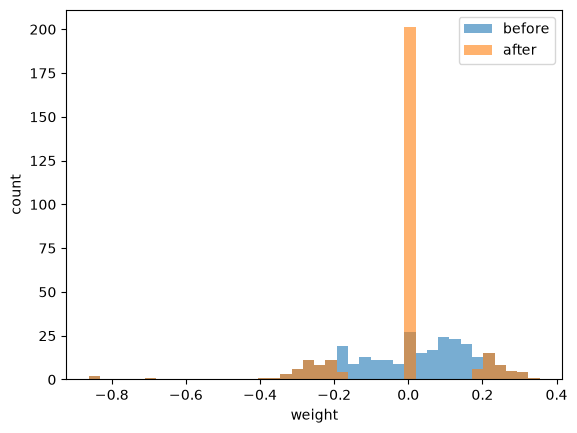

In [5]:
demo = reload_baseline()
layer_name, kernel = first_kernel(demo)
flat = kernel.reshape(-1)
cutoff = np.quantile(np.abs(flat), 0.7)
shown = flat.copy()
shown[np.abs(shown) <= cutoff] = 0
print("layer", layer_name)
print("before", np.round(flat[:8], 4))
print("after", np.round(shown[:8], 4))
print("zero fraction in this copy", float((shown == 0).mean()))
print("locked file was not changed")

fig, ax = plt.subplots()
ax.hist(flat, bins=40, alpha=0.6, label="before")
ax.hist(shown, bins=40, alpha=0.6, label="after")
ax.set_xlabel("weight")
ax.set_ylabel("count")
ax.legend()
save_plot(fig, "v3_prune_hist.png")
plt.show()
plt.close(fig)


**How to read this**

The before histogram is the first kernel as stored. The after histogram is a copy in which the smallest 70 percent of magnitudes were set to zero. The spike at 0 is those removed weights. The locked file is unchanged.


### Whole model

**What:** prune the reloaded baseline for 4 epochs and save a new TFLite file.

**Why:** frequency 100 and 4 epochs are the settings of the v2 pruned-float row. The final epoch is the one that finishes the sparsity schedule.


In [ ]:
model = reload_baseline()
steps = math.ceil(54000 / 128) * 4
schedule = tfmot.sparsity.keras.PolynomialDecay(
    initial_sparsity=0.0,
    final_sparsity=0.7,
    begin_step=0,
    end_step=steps,
    power=3,
    frequency=100,
)
pruned = tfmot.sparsity.keras.prune_low_magnitude(model, pruning_schedule=schedule)
pruned.compile(
    optimizer=tf_keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
pruned.fit(
    x_tr, y_tr,
    epochs=4,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[tfmot.sparsity.keras.UpdatePruningStep()],
)
stripped = tfmot.sparsity.keras.strip_pruning(pruned)
save_keras(stripped, "v3_pruned.keras")
path, _ = convert_float(stripped, "v3_pruned.tflite")
print("saved", path)
measure_saved("Pruned float v3", path)


Epoch 1/4
422/422 [==============================] - 18s 35ms/step - loss: 0.1622 - accuracy: 0.9411 - val_loss: 0.2156 - val_accuracy: 0.9215
Epoch 2/4
422/422 [==============================] - 11s 25ms/step - loss: 0.1984 - accuracy: 0.9284 - val_loss: 0.2342 - val_accuracy: 0.9137
Epoch 3/4
422/422 [==============================] - 9s 21ms/step - loss: 0.2303 - accuracy: 0.9175 - val_loss: 0.2356 - val_accuracy: 0.9127
Epoch 4/4
422/422 [==============================] - 11s 25ms/step - loss: 0.2284 - accuracy: 0.9189 - val_loss: 0.2301 - val_accuracy: 0.9170


FileExistsError: refusing to overwrite /home/haiminh/dl-10/test/v3_pruned.keras

**How to read this**

Test accuracy is the fraction of the 10,000 official test images this file labels correctly. The baseline accuracy is 0.9158. Loss in percentage points is `(0.9158 − test accuracy) × 100`. A positive loss means this file is less accurate than the baseline.

Raw KB and gzip KB are file size in bytes/1000. Gzip uses level 9 and `mtime=0`. Gzip cut compares that gzip size with the gzip size of `current/baseline_v2.tflite` (1567.603 KB). Raw cut is 1 − raw_KB / 1690.108, using `raw_KB` from `results/results.csv`.

p50 and p95 are the median of three latency passes on test image 0, in milliseconds. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor, in kB.

The cell prints one line for each bar: `accuracy bar (<= 2 pp)`, `raw bar (>= 50% raw cut)`, and `gzip bar (>= 50% gzip cut)`. Each line is PASS or FAIL. The verdict is PASS only when all three pass. FAIL (raw) means the raw bar failed. FAIL (acc) means the accuracy bar failed. The Keras–TFLite bar is not printed on this row.

The file is not smaller on disk because the zeros are still stored as float32, so it FAILs the raw bar and only shrinks after gzip. Saved row `pruned`: raw 1690.108 KB, raw cut 0.00%, gzip cut 60.31%, drop 0.59 pp, verdict FAIL (raw).


<a id="part-2"></a>
## Part 2. INT8 post-training quantization

**Goal:** Store the dense baseline as 8-bit integers and measure that file.

**Input:** `locked/baseline.keras`, reloaded for the demo and again for the conversion.

**Process:**
1. From the first kernel, compute a scale `S` and a zero-point `Z`, then rebuild weights as `r = S(q - Z)`.
2. Plot the float weights against the rebuilt values, and plot the rounding error.
3. Convert the reloaded baseline with `Optimize.DEFAULT`, the first 300 training images, integer-only ops, and int8 input and output.
4. Measure the saved TFLite file.

**Output:** `test/v3_int8.tflite`, `test/plots/v3_int8_scatter.png`, and `test/plots/v3_int8_error_hist.png`.

**Measurements:** test accuracy, raw .tflite KB, raw cut % = 1 − raw_KB / 1690.108, gzip KB, gzip cut %, median p50 and p95 latency, and peak memory. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor. Raw cut uses `raw_KB` from `results/results.csv`. The denominator 1690.108 is the float baseline `raw_KB`.

**Standard:** a compressed row passes only if the accuracy drop against 0.9158 is at most 2 percentage points, the raw cut is at least 50 percent, and the gzip cut is at least 50 percent. Keras–TFLite max output difference ≤ 1e-4 is checked once on the float model, in Part 0, from `results/equivalence.json`. It is not scored again on this row.


### A few weights

**What:** pick a scale and a zero-point from the first kernel, quantize four weights, and rebuild each real value as `r = S(q - Z)`.

**Why:** this is the affine map used by integer quantization. The scale here is only for this tensor demo. The next cell prints the scale stored in the converted file.


layer conv2d
S 0.004770581628762039 Z 127
r 0.1499660760164261 q 127 S(q - Z) 0.0
r 0.13642865419387817 q 127 S(q - Z) 0.0
r -0.1923178732395172 q 87 S(q - Z) -0.1908232569694519
r 0.10327216237783432 q 127 S(q - Z) 0.0
locked file was not changed


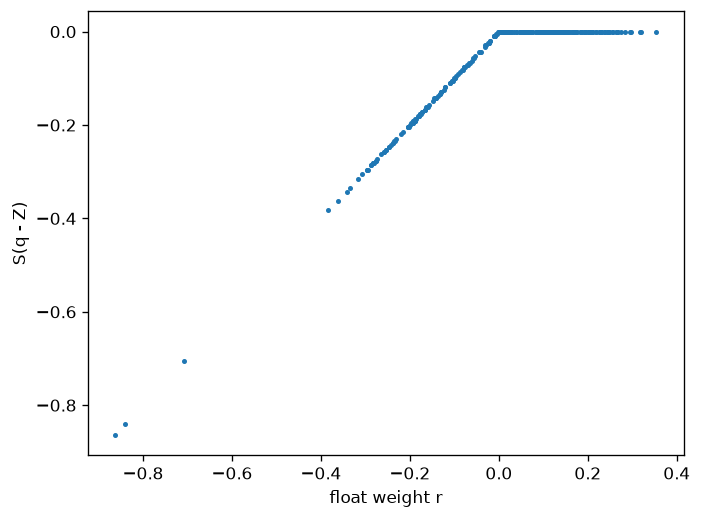

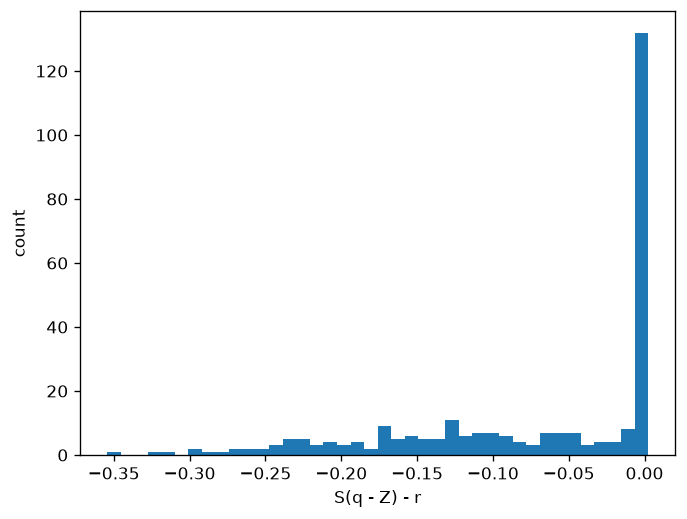

In [ ]:
demo = reload_baseline()
layer_name, kernel = first_kernel(demo)
values = kernel.reshape(-1)
low, high = float(values.min()), float(values.max())
scale = (high - low) / 255.0
zero = int(np.clip(np.round(-128 - low / scale), -128, 127))
sample = values[:4]
quantized = np.clip(np.round(sample / scale) + zero, -128, 127).astype(np.int8)
rebuilt = scale * (quantized.astype(np.float32) - zero)
print("layer", layer_name)
print("S", scale, "Z", zero)
for real, q, restored in zip(sample, quantized, rebuilt):
    print("r", float(real), "q", int(q), "S(q - Z)", float(restored))
print("locked file was not changed")

quant_all = np.clip(np.round(values / scale) + zero, -128, 127).astype(np.int8)
restored_all = scale * (quant_all.astype(np.float32) - zero)
fig, ax = plt.subplots()
ax.scatter(values, restored_all, s=4)
ax.set_xlabel("float weight r")
ax.set_ylabel("S(q - Z)")
save_plot(fig, "v3_int8_scatter.png")
plt.show()
fig, ax = plt.subplots()
ax.hist(restored_all - values, bins=40)
ax.set_xlabel("S(q - Z) - r")
ax.set_ylabel("count")
save_plot(fig, "v3_int8_error_hist.png")
plt.show()


**How to read this**

Each point is one weight in the first kernel. The horizontal position is the original float value `r`. The vertical position is the rebuilt value `S(q − Z)`. A point on the diagonal was rebuilt exactly. Distance from the diagonal is rounding error. This scale is the demo scale for this tensor, not the scale stored in the INT8 file.


**How to read this**

Each count is `S(q − Z) − r` for one weight. A narrow pile around 0 means the integer code is close to the original weight. Wider bars mean a coarser step between codes.


### Whole model

**What:** convert the reloaded baseline to a full-integer TFLite file and measure it.

**Why:** calibration uses the first 300 training images, the same count as the v2 INT8 row.


In [ ]:
model = reload_baseline()
path, payload = convert_int8(model, "v3_int8.tflite", 300)
interpreter = make_interpreter(path)
detail = interpreter.get_input_details()[0]
print("input S", detail["quantization"][0], "Z", detail["quantization"][1], "dtype", detail["dtype"])
print("saved", path)
measure_saved("INT8 baseline v3", path)


input S 0.003921568859368563 Z -128 dtype <class 'numpy.int8'>
saved /home/haiminh/dl-10/test/v3_int8.tflite
INT8 baseline v3: test 0.9150, loss 0.08 pp, raw 431.992 KB, raw cut 74.44%, gzip 383.123 KB, gzip cut 75.56%, p50 0.037 ms, p95 0.050 ms, VmHWM-floor 4764 kB
accuracy bar (<= 2 pp): PASS
raw bar (>= 50% raw cut): PASS
gzip bar (>= 50% gzip cut): PASS
verdict: PASS


**How to read this**

Test accuracy is the fraction of the 10,000 official test images this file labels correctly. The baseline accuracy is 0.9158. Loss in percentage points is `(0.9158 − test accuracy) × 100`. A positive loss means this file is less accurate than the baseline.

Raw KB and gzip KB are file size in bytes/1000. Gzip uses level 9 and `mtime=0`. Gzip cut compares that gzip size with the gzip size of `current/baseline_v2.tflite` (1567.603 KB). Raw cut is 1 − raw_KB / 1690.108, using `raw_KB` from `results/results.csv`.

p50 and p95 are the median of three latency passes on test image 0, in milliseconds. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor, in kB.

The cell prints one line for each bar: `accuracy bar (<= 2 pp)`, `raw bar (>= 50% raw cut)`, and `gzip bar (>= 50% gzip cut)`. Each line is PASS or FAIL. The verdict is PASS only when all three pass. FAIL (raw) means the raw bar failed. FAIL (acc) means the accuracy bar failed. The Keras–TFLite bar is not printed on this row.


<a id="part-3"></a>
## Part 3. Distillation

**Goal:** Train a width-8 student on the locked teacher's soft targets and measure that student.

**Input:** Soft targets from `locked/baseline.keras` on the training split, and a new `make_cnn(8)`.

**Process:**
1. Train a width-8 hard-label student for 10 epochs, batch 128, Adam defaults. Seed 42 is set immediately before `make_cnn(8)`. Keep the best validation epoch, save `test/v3_student_hard.tflite`, and measure it.
2. For training image 0, plot the teacher probabilities at temperature 1 and temperature 4.
3. Train 10 epochs at temperature 4 and alpha 0.5, batch 128, Adam defaults. Seed 42 is set immediately before that student is built.
4. Keep the epoch with the highest hard-label validation accuracy.
5. Save that student, convert it to float TFLite, and measure the file.

**Output:** `test/v3_student_hard.tflite`, `test/v3_distill.keras`, `test/v3_distill.tflite`, and `test/plots/v3_distill_bars.png`.

**Measurements:** test accuracy, raw .tflite KB, raw cut % = 1 − raw_KB / 1690.108, gzip KB, gzip cut %, median p50 and p95 latency, and peak memory. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor. Raw cut uses `raw_KB` from `results/results.csv`. The denominator 1690.108 is the float baseline `raw_KB`.

**Standard:** a compressed row passes only if the accuracy drop against 0.9158 is at most 2 percentage points, the raw cut is at least 50 percent, and the gzip cut is at least 50 percent. Keras–TFLite max output difference ≤ 1e-4 is checked once on the float model, in Part 0, from `results/equivalence.json`. It is not scored again on this row.


<a id="hard-label"></a>
### Hard-label student (small from-scratch baseline)

**What:** train a new `make_cnn(8)` on the hard labels for 10 epochs and measure the best validation epoch.

**Why:** this is the small from-scratch baseline. Distillation below uses the same width, seed, batch, and epoch count, with soft targets instead of hard labels.

**Output:** `test/v3_student_hard.tflite`.


In [ ]:
tf.random.set_seed(42)
np.random.seed(42)
student = make_cnn(8)
student.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
best = {"acc": -1.0, "epoch": None, "weights": None}
for epoch in range(10):
    student.fit(x_tr, y_tr, epochs=1, batch_size=128, shuffle=True, verbose=2)
    acc = float((student.predict(x_val, batch_size=256, verbose=0).argmax(1) == y_val).mean())
    print("val acc", epoch + 1, acc)
    if acc > best["acc"]:
        best = {"acc": acc, "epoch": epoch + 1, "weights": [item.copy() for item in student.get_weights()]}
student.set_weights(best["weights"])
print("kept epoch", best["epoch"], "val", best["acc"])
path, _ = convert_float(student, "v3_student_hard.tflite")
print("saved", path)
measure_saved("Small from-scratch model (same size)", path)


422/422 - 4s - loss: 0.6428 - accuracy: 0.7712 - 4s/epoch - 9ms/step
val acc 1 0.8525
422/422 - 3s - loss: 0.4011 - accuracy: 0.8573 - 3s/epoch - 7ms/step
val acc 2 0.873
422/422 - 3s - loss: 0.3492 - accuracy: 0.8746 - 3s/epoch - 7ms/step
val acc 3 0.8838333333333334
422/422 - 3s - loss: 0.3209 - accuracy: 0.8839 - 3s/epoch - 7ms/step
val acc 4 0.8895
422/422 - 3s - loss: 0.2982 - accuracy: 0.8921 - 3s/epoch - 7ms/step
val acc 5 0.8973333333333333
422/422 - 3s - loss: 0.2819 - accuracy: 0.8978 - 3s/epoch - 7ms/step
val acc 6 0.8966666666666666
422/422 - 3s - loss: 0.2687 - accuracy: 0.9032 - 3s/epoch - 7ms/step
val acc 7 0.9025
422/422 - 3s - loss: 0.2585 - accuracy: 0.9065 - 3s/epoch - 7ms/step
val acc 8 0.9033333333333333
422/422 - 3s - loss: 0.2495 - accuracy: 0.9090 - 3s/epoch - 7ms/step
val acc 9 0.9053333333333333
422/422 - 3s - loss: 0.2389 - accuracy: 0.9130 - 3s/epoch - 7ms/step
val acc 10 0.903
kept epoch 9 val 0.9053333333333333
saved /home/haiminh/dl-10/test/v3_student_har

**How to read this**

Test accuracy is the fraction of the 10,000 official test images this file labels correctly. The baseline accuracy is 0.9158. Loss in percentage points is `(0.9158 − test accuracy) × 100`. A positive loss means this file is less accurate than the baseline.

Raw KB and gzip KB are file size in bytes/1000. Gzip uses level 9 and `mtime=0`. Gzip cut compares that gzip size with the gzip size of `current/baseline_v2.tflite` (1567.603 KB). Raw cut is 1 − raw_KB / 1690.108, using `raw_KB` from `results/results.csv`.

p50 and p95 are the median of three latency passes on test image 0, in milliseconds. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor, in kB.

The cell prints one line for each bar: `accuracy bar (<= 2 pp)`, `raw bar (>= 50% raw cut)`, and `gzip bar (>= 50% gzip cut)`. Each line is PASS or FAIL. The verdict is PASS only when all three pass. FAIL (raw) means the raw bar failed. FAIL (acc) means the accuracy bar failed. The Keras–TFLite bar is not printed on this row.


### One image

**What:** print the teacher probability vector for training image 0, then the same vector softened at temperature 4.

**Why:** distillation trains on that softer target. This cell does not train the student.


hard label 9
T=1 [0.     0.     0.     0.     0.     0.     0.     0.0043 0.     0.9957]
T=4 [0.0027 0.0018 0.0019 0.0031 0.0042 0.038  0.0052 0.1887 0.0171 0.7373]


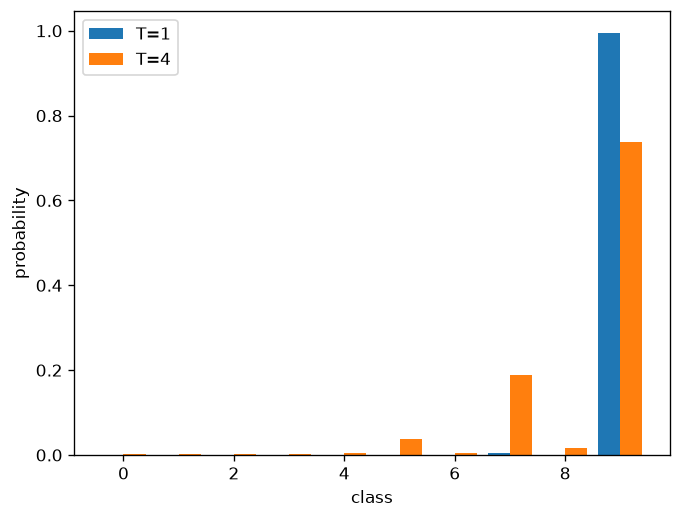

In [ ]:
teacher = reload_baseline()
probs = teacher.predict(x_tr[:1], verbose=0)[0]
temperature = 4.0
soft = np.power(probs, 1.0 / temperature)
soft = soft / soft.sum()
print("hard label", int(y_tr[0]))
print("T=1", np.round(probs, 4))
print("T=4", np.round(soft, 4))

fig, ax = plt.subplots()
classes = np.arange(10)
width = 0.4
ax.bar(classes - width / 2, probs, width, label="T=1")
ax.bar(classes + width / 2, soft, width, label="T=4")
ax.set_xlabel("class")
ax.set_ylabel("probability")
ax.legend()
save_plot(fig, "v3_distill_bars.png")
plt.show()
plt.close(fig)


**How to read this**

Each pair of bars is one class for training image 0. Temperature 1 is the teacher's own probability vector. Temperature 4 pulls the bars toward each other. That flatter vector is the soft target used in the distillation loss.


### Whole student

**What:** train the width-8 student on the teacher's training-set probabilities and save the best validation epoch.

**Why:** the checkpoint rule is hard-label validation accuracy, the same rule as the v2 distilled student.


In [ ]:
def distill_targets(teacher_probs, labels):
    return np.concatenate([teacher_probs.astype("float32"), labels.astype("float32")[:, None]], axis=1)

def make_distill_loss(temperature=4.0, alpha=0.5):
    def loss(y_true, y_pred):
        teacher = tf.clip_by_value(y_true[:, :10], 1e-8, 1.0)
        hard = tf.cast(y_true[:, 10], tf.int32)
        student = tf.clip_by_value(y_pred, 1e-8, 1.0)
        inv_t = 1.0 / temperature
        soft_teacher = tf.pow(teacher, inv_t)
        soft_student = tf.pow(student, inv_t)
        soft_teacher = soft_teacher / tf.reduce_sum(soft_teacher, axis=-1, keepdims=True)
        soft_student = soft_student / tf.reduce_sum(soft_student, axis=-1, keepdims=True)
        kl = tf.reduce_sum(soft_teacher * (tf.math.log(soft_teacher) - tf.math.log(soft_student)), axis=-1)
        hard_loss = tf_keras.losses.sparse_categorical_crossentropy(hard, y_pred)
        return (1.0 - alpha) * hard_loss + alpha * (temperature ** 2) * kl
    return loss

teacher = reload_baseline()
teacher_train = teacher.predict(x_tr, batch_size=256, verbose=0)
targets = distill_targets(teacher_train, y_tr)
tf.random.set_seed(42)
np.random.seed(42)
student = make_cnn(8)
student.compile(optimizer="adam", loss=make_distill_loss())
best = {"acc": -1.0, "epoch": None, "weights": None}
for epoch in range(10):
    student.fit(x_tr, targets, epochs=1, batch_size=128, shuffle=True, verbose=2)
    acc = float((student.predict(x_val, batch_size=256, verbose=0).argmax(1) == y_val).mean())
    print("val acc", epoch + 1, acc)
    if acc > best["acc"]:
        best = {"acc": acc, "epoch": epoch + 1, "weights": [item.copy() for item in student.get_weights()]}
student.set_weights(best["weights"])
print("kept epoch", best["epoch"], "val", best["acc"])
save_keras(student, "v3_distill.keras")
path, _ = convert_float(student, "v3_distill.tflite")
print("saved", path)
measure_saved("Distilled student v3", path)


422/422 - 2s - loss: 2.0506 - 2s/epoch - 5ms/step
val acc 1 0.846
422/422 - 2s - loss: 0.7957 - 2s/epoch - 4ms/step
val acc 2 0.8708333333333333
422/422 - 2s - loss: 0.6240 - 2s/epoch - 4ms/step
val acc 3 0.8796666666666667
422/422 - 2s - loss: 0.5333 - 2s/epoch - 6ms/step
val acc 4 0.8873333333333333
422/422 - 2s - loss: 0.4756 - 2s/epoch - 4ms/step
val acc 5 0.8948333333333334
422/422 - 2s - loss: 0.4356 - 2s/epoch - 4ms/step
val acc 6 0.8956666666666667
422/422 - 2s - loss: 0.4076 - 2s/epoch - 5ms/step
val acc 7 0.8988333333333334
422/422 - 2s - loss: 0.3851 - 2s/epoch - 5ms/step
val acc 8 0.902
422/422 - 2s - loss: 0.3677 - 2s/epoch - 4ms/step
val acc 9 0.9058333333333334
422/422 - 2s - loss: 0.3563 - 2s/epoch - 4ms/step
val acc 10 0.9063333333333333
kept epoch 10 val 0.9063333333333333
saved /home/haiminh/dl-10/test/v3_distill.tflite
Distilled student v3: test 0.9011, loss 1.47 pp, raw 415.612 KB, raw cut 75.41%, gzip 384.058 KB, gzip cut 75.50%, p50 0.016 ms, p95 0.017 ms, VmHWM-

**How to read this**

Test accuracy is the fraction of the 10,000 official test images this file labels correctly. The baseline accuracy is 0.9158. Loss in percentage points is `(0.9158 − test accuracy) × 100`. A positive loss means this file is less accurate than the baseline.

Raw KB and gzip KB are file size in bytes/1000. Gzip uses level 9 and `mtime=0`. Gzip cut compares that gzip size with the gzip size of `current/baseline_v2.tflite` (1567.603 KB). Raw cut is 1 − raw_KB / 1690.108, using `raw_KB` from `results/results.csv`.

p50 and p95 are the median of three latency passes on test image 0, in milliseconds. Peak memory is the median `VmHWM` of three fresh processes, minus the empty-process floor, in kB.

The cell prints one line for each bar: `accuracy bar (<= 2 pp)`, `raw bar (>= 50% raw cut)`, and `gzip bar (>= 50% gzip cut)`. Each line is PASS or FAIL. The verdict is PASS only when all three pass. FAIL (raw) means the raw bar failed. FAIL (acc) means the accuracy bar failed. The Keras–TFLite bar is not printed on this row.


<a id="part-4"></a>
## Part 4. Stacking

**Goal:** Build one model by naming the stages in order, then measure that file.

**Input:** The list in the configuration cell. This run starts from `locked/baseline.keras`.

**Process:** `run_stack` is defined once in the functions cell. The configuration cell only sets the order. The call cell runs that order. Names are `prune`, `distill`, and `int8`. If `int8` is included, it has to be last.

**Output:** A new file `test/stack_<order>_<time>.tflite`, one row in `ROWS`, and one row in `test/stack_runs.csv`.

**Measurements:** Same harness as Parts 1–3: test accuracy, raw .tflite KB, raw cut % = 1 − raw_KB / 1690.108, gzip KB, and gzip cut %. Raw cut uses `raw_KB` from `results/results.csv`.

**Standard:** Parts 1–3 files are not overwritten. Change the list, then run the call cell again. A compressed row passes only if the accuracy drop against 0.9158 is at most 2 percentage points, the raw cut is at least 50 percent, and the gzip cut is at least 50 percent. The saved stacked default row (`stacked, default config`, accuracy 0.8855, drop 3.03 pp, raw cut 93.41%, gzip cut 96.84%) is FAIL (acc). The Keras–TFLite bar is not scored on this row.


### Functions

**What:** `run_stack(order)` checks the order, then applies each name to the model returned by the previous name.

**Why:** The configuration cell should hold only the order. The training steps stay in this cell.


In [ ]:
def run_stack(order):
    """Build from the locked baseline in the given order, then measure the TFLite file."""
    import csv

    order = list(order)
    allowed = {"prune", "distill", "int8"}
    unknown = [name for name in order if name not in allowed]
    if unknown:
        raise ValueError("unknown stage: " + ", ".join(unknown))
    if len(order) != len(set(order)):
        raise ValueError("repeated stage")
    if "int8" in order and order[-1] != "int8":
        raise ValueError("int8 must be last")
    if not order:
        raise ValueError("order is empty")

    def distill_targets(teacher_probs, labels):
        return np.concatenate(
            [teacher_probs.astype("float32"), labels.astype("float32")[:, None]],
            axis=1,
        )

    def make_distill_loss(temperature=4.0, alpha=0.5):
        def loss(y_true, y_pred):
            teacher = tf.clip_by_value(y_true[:, :10], 1e-8, 1.0)
            hard = tf.cast(y_true[:, 10], tf.int32)
            student = tf.clip_by_value(y_pred, 1e-8, 1.0)
            inv_t = 1.0 / temperature
            soft_teacher = tf.pow(teacher, inv_t)
            soft_student = tf.pow(student, inv_t)
            soft_teacher = soft_teacher / tf.reduce_sum(soft_teacher, axis=-1, keepdims=True)
            soft_student = soft_student / tf.reduce_sum(soft_student, axis=-1, keepdims=True)
            kl = tf.reduce_sum(
                soft_teacher * (tf.math.log(soft_teacher) - tf.math.log(soft_student)),
                axis=-1,
            )
            hard_loss = tf_keras.losses.sparse_categorical_crossentropy(hard, y_pred)
            return (1.0 - alpha) * hard_loss + alpha * (temperature ** 2) * kl
        return loss

    state = {"targets": None, "from_distill": False}

    def do_distill(teacher):
        print("distill", flush=True)
        teacher_train = teacher.predict(x_tr, batch_size=256, verbose=0)
        state["targets"] = distill_targets(teacher_train, y_tr)
        tf.random.set_seed(42)
        np.random.seed(42)
        student = make_cnn(8)
        student.compile(optimizer="adam", loss=make_distill_loss())
        best = {"acc": -1.0, "epoch": None, "weights": None}
        for epoch in range(10):
            student.fit(
                x_tr, state["targets"],
                epochs=1, batch_size=128, shuffle=True, verbose=2,
            )
            acc = float((student.predict(x_val, batch_size=256, verbose=0).argmax(1) == y_val).mean())
            print("val acc", epoch + 1, acc)
            if acc > best["acc"]:
                best = {
                    "acc": acc,
                    "epoch": epoch + 1,
                    "weights": [item.copy() for item in student.get_weights()],
                }
        student.set_weights(best["weights"])
        print("kept epoch", best["epoch"], "val", best["acc"])
        state["from_distill"] = True
        return student

    def do_prune(model):
        from_distill = state["from_distill"]
        final_sparsity = float(STACK_PRUNE_SPARSITY)
        if not 0.0 < final_sparsity < 1.0:
            raise ValueError("STACK_PRUNE_SPARSITY must be between 0 and 1")
        print(
            "prune",
            "distillation loss" if from_distill else "hard labels",
            "sparsity",
            final_sparsity,
            flush=True,
        )
        steps = math.ceil(54000 / 128) * 4
        schedule = tfmot.sparsity.keras.PolynomialDecay(
            initial_sparsity=0.0,
            final_sparsity=final_sparsity,
            begin_step=0,
            end_step=steps,
            power=3,
            frequency=1 if from_distill else 100,
        )
        pruned = tfmot.sparsity.keras.prune_low_magnitude(model, pruning_schedule=schedule)
        if from_distill:
            pruned.compile(
                optimizer=tf_keras.optimizers.Adam(learning_rate=1e-4),
                loss=make_distill_loss(),
            )
            pruned.fit(
                x_tr, state["targets"],
                epochs=4,
                batch_size=128,
                callbacks=[tfmot.sparsity.keras.UpdatePruningStep()],
            )
        else:
            pruned.compile(
                optimizer=tf_keras.optimizers.Adam(learning_rate=1e-4),
                loss="sparse_categorical_crossentropy",
                metrics=["accuracy"],
            )
            pruned.fit(
                x_tr, y_tr,
                epochs=4,
                batch_size=128,
                validation_data=(x_val, y_val),
                callbacks=[tfmot.sparsity.keras.UpdatePruningStep()],
            )
        stripped = tfmot.sparsity.keras.strip_pruning(pruned)
        flat = np.concatenate([w.ravel() for w in stripped.get_weights()])
        print("zero fraction", round(float((flat == 0).mean()), 4))
        state["from_distill"] = False
        return stripped

    tf.random.set_seed(42)
    np.random.seed(42)
    model = reload_baseline()
    print("order", " ".join(order), flush=True)
    for name in order:
        if name == "prune":
            model = do_prune(model)
        elif name == "distill":
            model = do_distill(model)
        else:
            break

    stamp = time.strftime("%Y%m%d-%H%M%S")
    filename = "stack_" + "_".join(order) + "_" + stamp + ".tflite"
    label = "stack " + "+".join(order)
    if order[-1] == "int8":
        path, _ = convert_int8(model, filename, 300)
    else:
        path, _ = convert_float(model, filename)
    print("saved", path)
    row = measure_saved(label, path)

    log_path = os.path.join(TEST, "stack_runs.csv")
    fields = [
        "label", "order", "test_acc", "loss_pp", "raw_kb", "gzip_kb",
        "size_cut", "p50_ms", "p95_ms", "vm_delta_kb", "verdict", "path",
    ]
    new_file = not os.path.exists(log_path)
    with open(log_path, "a", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        if new_file:
            writer.writeheader()
        writer.writerow({
            "label": row["name"],
            "order": "+".join(order),
            "test_acc": f"{row['test_acc']:.4f}",
            "loss_pp": f"{row['loss_pp']:.2f}",
            "raw_kb": f"{row['raw_kb']:.3f}",
            "gzip_kb": f"{row['gzip_kb']:.3f}",
            "size_cut": f"{row['size_cut']:.2f}",
            "p50_ms": f"{row['p50_ms']:.3f}",
            "p95_ms": f"{row['p95_ms']:.3f}",
            "vm_delta_kb": int(row["vm_delta_kb"]),
            "verdict": verdict(row),
            "path": path,
        })
    print("stack csv", log_path)

    single_names = {
        "Pruned float v3",
        "INT8 baseline v3",
        "Small from-scratch model (same size)",
        "Distilled student v3",
    }
    singles = [item for item in ROWS if item["name"] in single_names and item is not row]
    print("single methods already measured in this kernel, then this stack")
    for item in singles + [row]:
        print(
            f"{item['name']:<42} {item['test_acc']:7.4f} {item['loss_pp']:7.2f} "
            f"{item['gzip_kb']:10.3f} {item['size_cut']:7.2f} "
            f"{item['p50_ms']:7.3f} {item['p95_ms']:7.3f}"
        )
    view = singles + [row]
    half_kb = (BASE_GZIP / 2) / 1000
    fig, ax = plt.subplots(figsize=(7, 5))
    for item in view:
        ax.scatter(item["gzip_kb"], item["loss_pp"])
        ax.annotate(item["name"], (item["gzip_kb"], item["loss_pp"]), fontsize=7)
    ax.axhline(2.0, linestyle="--", color="gray")
    ax.axvline(half_kb, linestyle="--", color="gray")
    ax.set_xlabel("gzip KB")
    ax.set_ylabel("accuracy loss (pp)")
    plt.show()
    plt.close(fig)
    return row


### Configuration

**What:** The order of stages, and the sparsity used when that order contains `prune`. Nothing here trains.

**Why:** Change the list when you want another combination. `int8`, when used, stays last. `STACK_PRUNE_SPARSITY` is only for this stack. Part 1 still uses 0.70.


In [ ]:
# Names: "prune", "distill", "int8".
# If "int8" is in the list, it has to be last.
PIPELINE = ["distill", "prune", "int8"]
# Part 1 prunes the wide model to 0.70. The same target on the width-8
# student left the three-step file at 3.03 pp. 0.30 removes fewer weights.
STACK_PRUNE_SPARSITY = 0.30


### Call

**What:** Build and measure the model named by `PIPELINE`.

**Why:** The call passes the list through. This configuration is distillation, then pruning at `STACK_PRUNE_SPARSITY`, then INT8.


In [ ]:
run_stack(PIPELINE)


**How to read this**

The printed row is the file this stack just wrote. Test accuracy is the fraction of the 10,000 official test images that file labels correctly. Loss in percentage points is `(0.9158 − test accuracy) × 100`. Gzip KB uses level 9 and `mtime=0`. The lines `accuracy bar`, `raw bar`, and `gzip bar` are PASS or FAIL. The saved default stack (drop 3.03 pp, raw cut 93.41%, gzip cut 96.84%) is FAIL (acc).

The plot puts that stack next to any single-method rows already measured in this kernel. Parts 1–3 keep their own saved outputs above, whether or not this kernel has rerun them.


<a id="final"></a>
## Final comparison

**What:** print every measured row, then save two plots.

**Why:** the table uses the same columns as the v2 results, plus PASS/FAIL and peak memory. The float baseline row reads `current/baseline_v2.tflite` and does not write it. A compression row passes only when the accuracy drop is at most 2 pp and both the raw cut and the gzip cut are at least 50 percent. The baseline row is marked `reference`. `pruned` is FAIL (raw). `stacked, default config` is FAIL (acc).


Row                                                 Test    Loss     Raw KB  Raw cut    Gzip KB Gzip cut     p50     p95  Vm-floor       Result
Float baseline v2 (existing file, not written)    0.9158    0.00   1690.108     0.00   1567.603     0.00   0.155   0.226      7108    reference
Pruned float v3                                   0.9099    0.59   1690.108     0.00    622.146    60.31   0.179   0.261      7244   FAIL (raw)
INT8 baseline v3                                  0.9150    0.08    431.992    74.44    383.123    75.56   0.068   0.079      4684         PASS
Small from-scratch model (same size)              0.8974    1.84    415.612    75.41    384.088    75.50   0.025   0.028      4692         PASS
Distilled student v3                              0.9011    1.47    415.612    75.41    384.058    75.50   0.025   0.029      4636         PASS
Pruned rerun INT8 v3                              0.9102    0.56    431.992    74.44    181.994    88.39   0.070   0.094      4648      

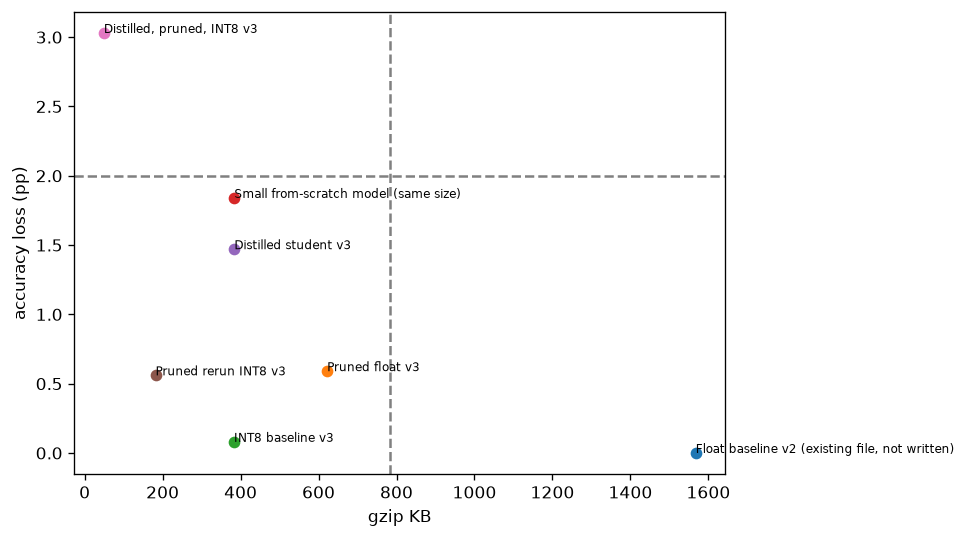

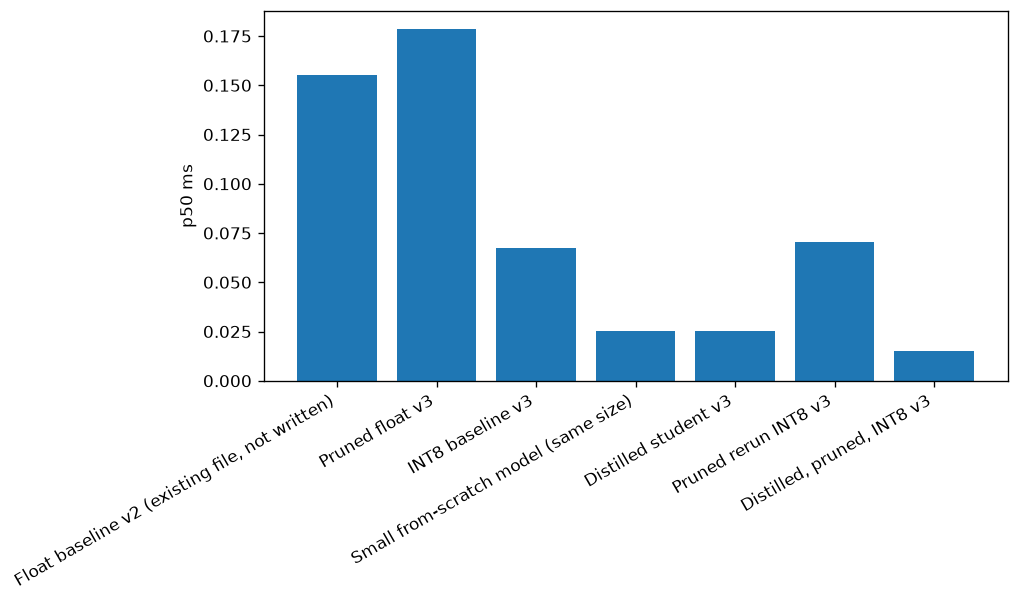

In [ ]:
baseline_path = os.path.join(ROOT, "current/baseline_v2.tflite")
payload = open(baseline_path, "rb").read()
vm_median, vm_delta = peak_delta(baseline_path)
baseline_row = {
    "name": "Float baseline v2 (existing file, not written)",
    "file": "baseline_v2.tflite",
    "test_acc": tflite_accuracy(baseline_path, x_te, y_te),
    "raw_kb": len(payload) / 1000,
    "gzip_kb": gzip_size(payload) / 1000,
    "size_cut": 0.0,
    "reference": True,
    "vmhwm_kb": vm_median,
    "vm_delta_kb": vm_delta,
}
baseline_row["loss_pp"] = (REF_ACC - baseline_row["test_acc"]) * 100
baseline_row["raw_cut"] = raw_cut_pct(baseline_row["raw_kb"])
baseline_row["p50_ms"], baseline_row["p95_ms"] = latency_medians(baseline_path)
table = [baseline_row] + ROWS
header = (
    f"{'Row':<48} {'Test':>7} {'Loss':>7} {'Raw KB':>10} {'Raw cut':>8} "
    f"{'Gzip KB':>10} {'Gzip cut':>8} {'p50':>7} {'p95':>7} "
    f"{'Vm-floor':>9} {'Result':>12}"
)
print(header)
for row in table:
    print(
        f"{row['name']:<48} {row['test_acc']:7.4f} {row['loss_pp']:7.2f} "
        f"{row['raw_kb']:10.3f} {row['raw_cut']:8.2f} "
        f"{row['gzip_kb']:10.3f} {row['size_cut']:8.2f} "
        f"{row['p50_ms']:7.3f} {row['p95_ms']:7.3f} {row['vm_delta_kb']:9d} {verdict(row):>12}"
    )
print_row(baseline_row)
for row in ROWS:
    print_row(row)

half_kb = (BASE_GZIP / 2) / 1000
fig, ax = plt.subplots(figsize=(7, 5))
for row in table:
    ax.scatter(row["gzip_kb"], row["loss_pp"])
    ax.annotate(row["name"], (row["gzip_kb"], row["loss_pp"]), fontsize=7)
ax.axhline(2.0, linestyle="--", color="gray")
ax.axvline(half_kb, linestyle="--", color="gray")
ax.set_xlabel("gzip KB")
ax.set_ylabel("accuracy loss (pp)")
save_plot(fig, "v3_loss_vs_gzip.png")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(table)), [row["p50_ms"] for row in table])
ax.set_xticks(range(len(table)))
ax.set_xticklabels([row["name"] for row in table], rotation=30, ha="right")
ax.set_ylabel("p50 ms")
save_plot(fig, "v3_p50.png")
plt.show()
plt.close(fig)

import json as _json
_csv_name = {
    "baseline_v2.tflite": "float baseline",
    "v3_student_hard.tflite": "small from-scratch",
    "v3_pruned.tflite": "pruned",
    "v3_int8.tflite": "INT8",
    "v3_distill.tflite": "distilled student",
    "v3_pruned_int8.tflite": "pruned INT8",
    "v3_distill_pruned_int8.tflite": "distilled pruned INT8",
}
_raw = {"ref_acc": REF_ACC, "rows": []}
for row in table:
    if row["file"] == "baseline_v2.tflite":
        path = os.path.join(ROOT, "current", row["file"])
    else:
        path = os.path.join(TEST, row["file"])
    payload = open(path, "rb").read()
    _raw["rows"].append({
        "row": _csv_name[row["file"]],
        "file": row["file"],
        "path": path,
        "test_acc": row["test_acc"],
        "acc_drop_pp": row["loss_pp"],
        "raw_bytes": len(payload),
        "gzip_bytes": gzip_size(payload),
        "size_cut_pct": row["size_cut"],
        "p50_ms": row["p50_ms"],
        "p95_ms": row["p95_ms"],
        "peak_mem_kB": row["vm_delta_kb"],
        "verdict": verdict(row),
    })
_raw_path = os.path.join(ROOT, "results", "raw_measurements.json")
with open(_raw_path, "w") as handle:
    _json.dump(_raw, handle, indent=2)
    handle.write("\n")
print("wrote", _raw_path)


**How to read this**

Each point is one row. Horizontal position is gzip size in KB. Vertical position is accuracy loss in percentage points against 0.9158. The dashed horizontal line is the 2 pp bar. The dashed vertical line is the gzip size of a 50 percent cut. The safe corner is below the horizontal line and to the left of the vertical line.


**How to read this**

Each bar is the median p50 latency of that row, in milliseconds, on test image 0. A shorter bar is a faster median invoke. The height is not accuracy and it is not file size.


## Requirements checklist

| DL-10 brief item | Cell that does it |
|---|---|
| Fixed test set | Cell 5 slices the official Fashion-MNIST sets with no shuffle: 54,000 train, last 6,000 validation, 10,000 official test. Cell 7 evaluates the locked model on that test set. |
| At least two compression methods | Pruning is the Part 1 whole-model cell, INT8 is the Part 2 whole-model cell, and distillation is the Part 3 whole-student cell. Part 4 runs the order in `PIPELINE`. |
| Accuracy drop at most 2 percentage points | Cell 9 `bar_flags` (loss ≤ 2 pp against 0.9158). Each measured cell and cell 44 print PASS or FAIL. |
| p50 and p95, at least 20 warm-up runs and 200 timed runs | Cell 9 `latency_medians`: 20 warm-up calls, 200 timed calls, three passes, median of the three. Cell 43 prints p50 and p95. |
| Size in MB and at least a 50 percent cut on raw and on gzip | Cell 44 prints Raw KB, raw cut % = 1 − raw_KB / 1690.108, Gzip KB, and gzip cut %. Cell 9 `bar_flags` passes a row only when both the raw cut and the gzip cut are at least 50 percent. |
| Peak-memory table | Cell 9 `peak_delta`: median `VmHWM` of three fresh processes, minus the empty-process floor. Cell 43 column `Vm-floor`. |
| Small from-scratch model at the same size | Cell 27: `make_cnn(8)`, seed 42, hard labels, 10 epochs, best validation epoch. Same width as the distilled student. |
| Keras-versus-TFLite difference at most 1e-4 | Checked once on the float model. `results/equivalence.json` records 1.7583370208740234e-6 on all 10,000 official test images, PASS. Not scored per compressed row. |


## AI usage statement

- Grok CLI 1.0.88 (2fe3608f7398): the v3 notebook structure, the measurement harness, the folder layout, running the notebook sections, and this packaging (megabyte columns, the small from-scratch row, `results/results.csv`, `requirements.txt`, and this README-facing checklist).
- Other tools: (fill in any other assistant, website, or classmate help you used).
